# code_126 · Coherent trajectories, quantiles and changing regimes

**Book:** section 24.6. A self-contained forecasting laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_24_GUIDE.md), [run evidence](../CHAPTER_24_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_126).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2726;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
import statsmodels
VERSIONS['statsmodels']=statsmodels.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2726


<a id="hierarchical-probabilistic-contract"></a>
 ## Coherent forecast draws do not make marginal quantiles additive
 Generate nine member-demand series in three buildings, plus their building totals and grand total (13series). Observed outcomes obey the exact aggregation matrix. Independently fit all thirteen Ridge models on source data before1440hours; calibrate forecast-error covariances and residual scenarios using origins1440–2136, before final origins2160–2856. Daily origins predict hours1/6/24, all within one known low/high daily operating regime. Every forecast refreshes its admitted48-hour context but parameters/calibration remain frozen. A response/noise shift begins at2520, unannounced to the model. Reconciliation uses linear solves and a positive-definite shrinkage covariance per horizon. Joint scenarios resample whole calibration-origin residual blocks across every series/horizon, either pooled or conditional on the known regime, then project each draw. Assess pinball loss, central80% interval coverage and width by horizon, hierarchy level, regime and before/after shift. Finite calibration groups and temporal/within-hierarchy dependence are explicit.


,period,level,horizon,method,MSE
0,Before shift,Grand total,1,Base,4.200045
1,Before shift,Grand total,1,Reconciled,4.186793
2,Before shift,Grand total,6,Base,3.049738
3,Before shift,Grand total,6,Reconciled,2.947284
4,Before shift,Grand total,24,Base,4.556367
5,Before shift,Grand total,24,Reconciled,4.272964
6,Before shift,Buildings,1,Base,1.721776
7,Before shift,Buildings,1,Reconciled,1.698816
8,Before shift,Buildings,6,Base,1.302766
9,Before shift,Buildings,6,Reconciled,1.289657


,period,operating_regime,level,horizon,method,origin_count,series_count,case_count,coverage80,mean_width,mean_pinball_three_quantiles
0,Before shift,0,Grand total,1,Base pooled,8,1,8,0.875000,3.574002,0.237464
1,Before shift,0,Grand total,1,Reconciled pooled,8,1,8,0.875000,3.418657,0.243529
2,Before shift,0,Grand total,1,Reconciled regime,8,1,8,0.750000,2.899069,0.249170
3,Before shift,0,Grand total,6,Base pooled,8,1,8,1.000000,7.678175,0.374847
4,Before shift,0,Grand total,6,Reconciled pooled,8,1,8,1.000000,7.763012,0.363196
...,...,...,...,...,...,...,...,...,...,...,...
103,After shift,1,Members,6,Reconciled pooled,8,9,72,0.305556,1.543068,0.694017
104,After shift,1,Members,6,Reconciled regime,8,9,72,0.444444,2.174252,0.653373
105,After shift,1,Members,24,Base pooled,8,9,72,0.263889,1.315297,0.633351
106,After shift,1,Members,24,Reconciled pooled,8,9,72,0.277778,1.313432,0.632328


Coherence: 2.8110461105395927 2.842170943040401e-14 {'Base pooled': 3.2128812024722286, 'Reconciled pooled': 5.684341886080802e-14, 'Reconciled regime': 5.684341886080802e-14} marginal quantile gap: 3.1139668735422674 calibration groups: {'0': 15, '1': 15}


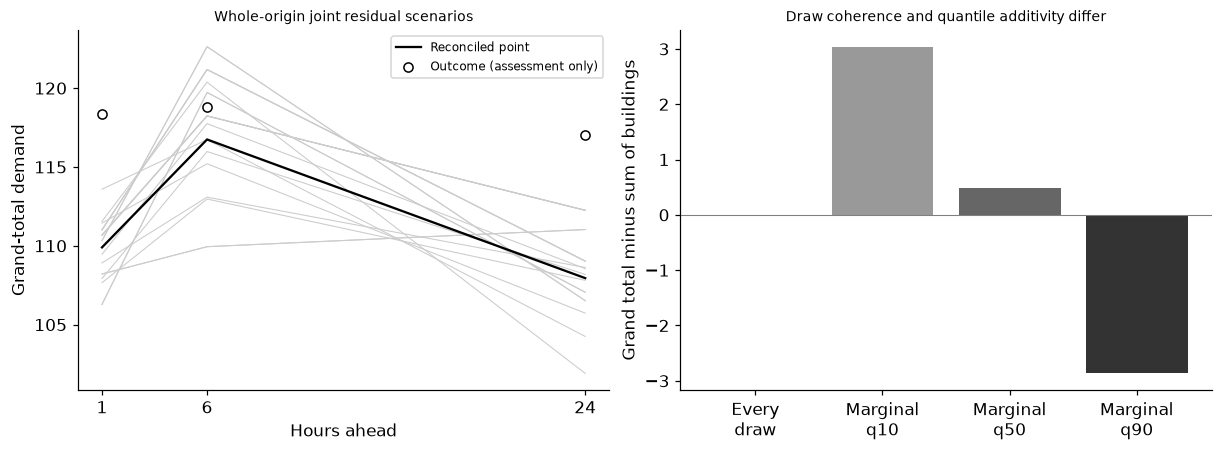

In [2]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
T=2880;horizons=np.array([1,6,24]);clock=np.arange(T);regime=(clock//24)%2;hour=clock%24;shock_at=2520;member_base=rng.uniform(8,12,9);area=rng.uniform(.8,1.2,9);noise=np.zeros((T,9));leaf=np.zeros((T,9))
for t in range(T):
    shifted=t>=shock_at;sd=.25 if regime[t]==0 else (1.8 if shifted else .9);shared=np.repeat(rng.normal(size=3),3);innovation=sd*(.5*shared+.6*rng.normal(size=9));noise[t]=(.4*noise[t-1] if t else 0)+innovation;extra=np.zeros(9)
    if shifted and regime[t]:extra[:3]=3
    leaf[t]=member_base+area*(1.2*np.sin(2*np.pi*hour[t]/24)+.5*np.cos(2*np.pi*hour[t]/24)+2*regime[t])+extra+noise[t]
S=np.zeros((13,9));S[0]=1
for b in range(3):S[1+b,3*b:3*b+3]=1
S[4:]=np.eye(9);series=leaf@S.T;constraint=np.zeros((4,13));constraint[0,0]=1;constraint[0,1:4]=-1
for b in range(3):constraint[1+b,1+b]=1;constraint[1+b,4+3*b:7+3*b]=-1
np.testing.assert_array_equal(constraint@S,0);np.testing.assert_allclose(series@constraint.T,0,atol=1e-12)
source_origins=np.arange(48,1440-24+1,24);calibration_origins=np.arange(1440,2160-24+1,24);final_origins=np.arange(2160,T-24+1,24)
def design(node,origins):
    rows=[]
    for origin in origins:
        future=origin+horizons-1;rows.append(np.r_[series[origin-1,node],series[origin-24,node],series[origin-24:origin,node].mean(),np.sin(2*np.pi*hour[future]/24),np.cos(2*np.pi*hour[future]/24),regime[future]])
    return np.array(rows)
def targets(origins):return np.array([series[origin+horizons-1].T for origin in origins])
source_truth=targets(source_origins);calibration_truth=targets(calibration_origins);final_truth=targets(final_origins);base_calibration=np.empty_like(calibration_truth);base_final=np.empty_like(final_truth);models=[]
for node in range(13):
    model=make_pipeline(StandardScaler(),Ridge(alpha=1));model.fit(design(node,source_origins),source_truth[:,node]);base_calibration[:,node]=model.predict(design(node,calibration_origins));base_final[:,node]=model.predict(design(node,final_origins));models.append(model)
errors=calibration_truth-base_calibration;projection=[];minimum_eigenvalues=[]
for h in range(3):
    sample_cov=np.cov(errors[:,:,h],rowvar=False,ddof=1);W=.8*np.diag(np.diag(sample_cov))+.2*sample_cov+np.eye(13)*1e-8;minimum_eigenvalues.append(float(np.linalg.eigvalsh(W).min()));weighted_S=np.linalg.solve(W,S);P=S@np.linalg.solve(S.T@weighted_S,weighted_S.T);np.testing.assert_allclose(P@S,S,atol=1e-12);np.testing.assert_allclose(P@P,P,atol=1e-12);projection.append(P);np.testing.assert_allclose(S.T@np.linalg.solve(W,P@base_final[0,:,h]-base_final[0,:,h]),0,atol=1e-9)
projection=np.array(projection)
def reconcile(values):return np.einsum('hij,...jh->...ih',projection,values)
reconciled_final=reconcile(base_final);base_gap=float(np.max(np.abs(np.einsum('cm,nmh->nch',constraint,base_final))));reconciled_gap=float(np.max(np.abs(np.einsum('cm,nmh->nch',constraint,reconciled_final))));assert base_gap>1e-6 and reconciled_gap<1e-10
calibration_regime=regime[calibration_origins];final_regime=regime[final_origins];assert all(np.all(regime[o+horizons-1]==regime[o]) for o in np.r_[calibration_origins,final_origins]);group_counts={str(r):int(np.sum(calibration_regime==r)) for r in [0,1]};draw_count=400;scenario_sets={'Base pooled':[],'Reconciled pooled':[],'Reconciled regime':[]}
for index,origin in enumerate(final_origins):
    selected=rng.integers(0,len(errors),draw_count);pooled=base_final[index]+errors[selected];eligible=np.flatnonzero(calibration_regime==regime[origin]);selected_regime=rng.choice(eligible,draw_count,replace=True);conditional=base_final[index]+errors[selected_regime];scenario_sets['Base pooled'].append(pooled);scenario_sets['Reconciled pooled'].append(reconcile(pooled));scenario_sets['Reconciled regime'].append(reconcile(conditional))
scenario_sets={name:np.array(values) for name,values in scenario_sets.items()};quantile_levels=np.array([.1,.5,.9]);quantiles={name:np.quantile(values,quantile_levels,axis=1).transpose(1,0,2,3) for name,values in scenario_sets.items()};scenario_gaps={name:float(np.max(np.abs(np.einsum('cm,ndmh->ndch',constraint,values)))) for name,values in scenario_sets.items()};assert scenario_gaps['Reconciled regime']<1e-10 and scenario_gaps['Reconciled pooled']<1e-10
marginal_gap=float(np.max(np.abs(np.einsum('cm,nqmh->nqch',constraint,quantiles['Reconciled regime']))));assert marginal_gap>1e-5
levels={'Grand total':np.array([0]),'Buildings':np.arange(1,4),'Members':np.arange(4,13)};interval_rows=[];point_rows=[]
for period,period_mask in [('Before shift',final_origins<shock_at),('After shift',final_origins>=shock_at)]:
    for level,nodes in levels.items():
        for h_index,horizon in enumerate(horizons):
            for method,prediction in [('Base',base_final),('Reconciled',reconciled_final)]:point_rows.append({'period':period,'level':level,'horizon':int(horizon),'method':method,'MSE':float(np.mean((prediction[period_mask][:,nodes,h_index]-final_truth[period_mask][:,nodes,h_index])**2))})
    for operating_regime in [0,1]:
        case=period_mask&(final_regime==operating_regime)
        for level,nodes in levels.items():
            for h_index,horizon in enumerate(horizons):
                truth=final_truth[case][:,nodes,h_index]
                for method,q in quantiles.items():
                    interval=q[case][:,:,nodes,h_index];low=interval[:,0];high=interval[:,2];error=truth[:,None,:]-interval;pinball=np.maximum(quantile_levels[None,:,None]*error,(quantile_levels[None,:,None]-1)*error);interval_rows.append({'period':period,'operating_regime':operating_regime,'level':level,'horizon':int(horizon),'method':method,'origin_count':int(case.sum()),'series_count':len(nodes),'case_count':int(case.sum()*len(nodes)),'coverage80':float(np.mean((truth>=low)&(truth<=high))),'mean_width':float(np.mean(high-low)),'mean_pinball_three_quantiles':float(pinball.mean())})
RESULTS.update(point_assessment=point_rows,interval_assessment=interval_rows,hierarchy={'bottom_members':9,'buildings':3,'all_series':13,'summing_matrix_shape':list(S.shape)},horizons=horizons.tolist(),origin_counts={'source':len(source_origins),'calibration':len(calibration_origins),'final':len(final_origins)},calibration_origin_counts_by_regime=group_counts,draws_per_origin=draw_count,base_point_coherence_max_error=base_gap,reconciled_point_coherence_max_error=reconciled_gap,scenario_coherence_max_errors=scenario_gaps,reconciled_marginal_quantile_coherence_max_error=marginal_gap,weight_covariance_minimum_eigenvalues=minimum_eigenvalues,shift_begins_at_hour=shock_at,final_begins_at_hour=2160,minimum_reconciled_scenario_value=float(scenario_sets['Reconciled regime'].min()),source_only_model_fit=True,calibration_frozen_before_final=True);display(pd.DataFrame(point_rows));display(pd.DataFrame(interval_rows));print('Coherence:',base_gap,reconciled_gap,scenario_gaps,'marginal quantile gap:',marginal_gap,'calibration groups:',group_counts)
example=int(np.flatnonzero((final_origins>=shock_at)&(final_regime==1))[0]);draws=scenario_sets['Reconciled regime'][example];q=quantiles['Reconciled regime'][example];fig,axes=plt.subplots(1,2,figsize=(11,4))
for draw in draws[:20]:axes[0].plot(horizons,draw[0],color='.8',linewidth=.7)
axes[0].plot(horizons,reconciled_final[example,0],color='black',label='Reconciled point');axes[0].scatter(horizons,final_truth[example,0],facecolors='white',edgecolors='black',label='Outcome (assessment only)');axes[0].set(xticks=horizons,xlabel='Hours ahead',ylabel='Grand-total demand',title='Whole-origin joint residual scenarios');axes[0].legend(fontsize=8)
residuals=[0.]+[float(q[i,0,-1]-q[i,1:4,-1].sum()) for i in range(3)];axes[1].bar(range(4),residuals,color=['.8','.6','.4','.2']);axes[1].axhline(0,color='.5',linewidth=.7);axes[1].set(xticks=range(4),xticklabels=['Every\ndraw','Marginal\nq10','Marginal\nq50','Marginal\nq90'],ylabel='Grand total minus sum of buildings',title='Draw coherence and quantile additivity differ');plt.show()


<a id="forecast-uncertainty-limits"></a>
 ## Projection is a coherence calculation, not a coverage guarantee
 Covariance shrinkage uses thirty calibration origins, with fifteen per known daily regime. Whole-origin residual blocks retain the observed cross-series/cross-horizon association; 400 resamples do not create 400 independent calibration cases. Reconciliation uses the declared estimated weighted metric and does not promise uniformly improved error, nonnegativity or correct distribution tails. Each projected draw obeys the hierarchy, but separately taking nodewise quantiles generally breaks additive equalities. A central80% marginal interval is not an80% simultaneous trajectory or all-building coverage statement. The later unannounced mean/noise shift changes the relationship; frozen calibration need not maintain nominal coverage. Contexts after the shift can contain admitted earlier shifted observations without constituting a parameter/calibration refit. Scores retain horizons, hierarchy levels, regime and independent-origin counts rather than treating every member and horizon as an independent new case.


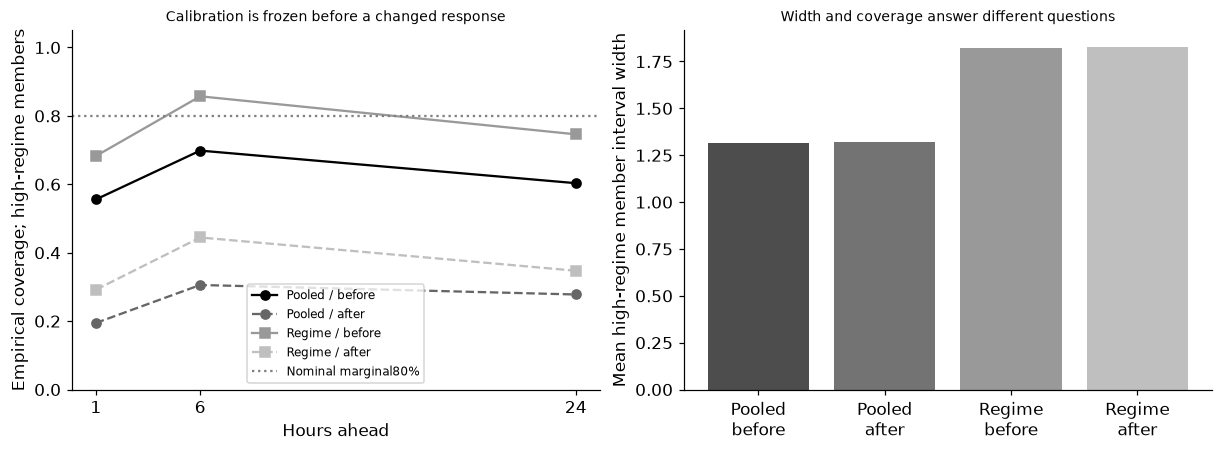

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4));styles={('Reconciled pooled','Before shift'):('o-','black'),('Reconciled pooled','After shift'):('o--','.4'),('Reconciled regime','Before shift'):('s-','.6'),('Reconciled regime','After shift'):('s--','.75')};widths=[];labels=[]
for (method,period),(style,color) in styles.items():
    subset=[r for r in interval_rows if r['method']==method and r['period']==period and r['operating_regime']==1 and r['level']=='Members'];subset=sorted(subset,key=lambda r:r['horizon']);label=('Pooled' if method.endswith('pooled') else 'Regime')+(' / before' if period=='Before shift' else ' / after');axes[0].plot([r['horizon'] for r in subset],[r['coverage80'] for r in subset],style,color=color,label=label);widths.append(float(np.mean([r['mean_width'] for r in subset])));labels.append(label.replace(' / ','\n'))
axes[0].axhline(.8,color='.5',linestyle=':',label='Nominal marginal80%');axes[0].set(xticks=horizons,ylim=(0,1.05),xlabel='Hours ahead',ylabel='Empirical coverage; high-regime members',title='Calibration is frozen before a changed response');axes[0].legend(fontsize=8)
axes[1].bar(range(4),widths,color=['.3','.45','.6','.75']);axes[1].set(xticks=range(4),xticklabels=labels,ylabel='Mean high-regime member interval width',title='Width and coverage answer different questions');plt.show()
assert all(0<=r['coverage80']<=1 and np.isfinite(r['mean_pinball_three_quantiles']) for r in interval_rows)


In [4]:
summary={'example_id':'code_126','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual all-level forecast reconciliation', 'calibration-only shrinkage covariance', 'whole-origin multi-horizon residual scenarios', 'coherent draws versus nonadditive marginal quantiles', 'coverage pinball width by regime horizon and level'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual all-level forecast reconciliation", "calibration-only shrinkage covariance", "whole-origin multi-horizon residual scenarios", "coherent draws versus nonadditive marginal quantiles", "coverage pinball width by regime horizon and level"], "elapsed_seconds": 0.977, "example_id": "code_126", "hardware": "Darwin arm64 CPU", "results": {"base_point_coherence_max_error": 2.8110461105395927, "calibration_frozen_before_final": true, "calibration_origin_counts_by_regime": {"0": 15, "1": 15}, "draws_per_origin": 400, "final_begins_at_hour": 2160, "hierarchy": {"all_series": 13, "bottom_members": 9, "buildings": 3, "summing_matrix_shape": [13, 9]}, "horizons": [1, 6, 24], "interval_assessment": [{"case_count": 8, "coverage80": 0.875, "horizon": 1, "level": "Grand total", "mean_pinball_three_quantiles": 0.2374639729553135, "mean_width": 3.574001869436044, "method": "Base pooled", "operating_regime": 0, "origin_count": 8, "period": "Before sh